In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.cross_decomposition import PLSRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.model_selection import RandomizedSearchCV,GridSearchCV
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.impute import KNNImputer
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, classification_report
from sklearn.inspection import permutation_importance
from sklearn.metrics import roc_auc_score,roc_curve, make_scorer, auc

# Data

In [ ]:

url = "https://raw.githubusercontent.com/CIMCB/MetabComparisonBinaryML/master/notebooks/data/MTBLS90.xlsx"

data = pd.read_excel(url, sheet_name="Data")
peak = pd.read_excel(url, sheet_name="Peak")


/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)
/usr/local/lib/python3.11/dist-packages/openpyxl/worksheet/_reader.py:329: UserWarning: Unknown extension is not supported and will be removed
  warn(msg)


There are no nans in the table yay

In [ ]:
x = data.iloc[:, 4:]
y = data.iloc[:, 2]

print("Raw data NaNs: in features -  "+ str(np.any(np.isnan(x)))+", in labels - " + str(np.any(np.isnan(y))))
print("Raw data inf. numbers: in features -  "+ str(np.any(np.isinf(x)))+", in labels - " + str(np.any(np.isinf(y))))

Raw data NaNs: in features -  False, in labels - False
Raw data inf. numbers: in features -  False, in labels - False


In [ ]:
#split data
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=(1/3), stratify=y ,random_state=42)

#scale data (imputation is not needed, no nans)
scaler = StandardScaler()

x_train_log = np.log(x_train)
x_train = scaler.fit_transform(x_train_log)

x_test_log = np.log(x_test)
x_test = scaler.transform(x_test_log)

print("Scaled data NaNs: in train -  "+ str(np.any(np.isnan(x_train)))+", in test - " + str(np.any(np.isnan(x_test))))
print("Scaled data inf. numbers: in train -  "+ str(np.any(np.isinf(x_train)))+", in test - " + str(np.any(np.isinf(x_test))))

Scaled data NaNs: in train -  False, in test - False
Scaled data inf. numbers: in train -  False, in test - False


# Partial Least Squares Regression

In [ ]:
param_dist = {
    'n_components': list(range(1,6))
}


rf = PLSRegression()

random_search_plsr = GridSearchCV( rf, param_grid=param_dist,
    cv=5,
    verbose=2,
    n_jobs=-1,
    scoring="r2" #better for this type
)

random_search_plsr.fit(x_train, y_train)


Fitting 5 folds for each of 5 candidates, totalling 25 fits


GridSearchCV(cv=5, estimator=PLSRegression(), n_jobs=-1,
             param_grid={'n_components': [1, 2, 3, 4, 5]}, scoring='r2',
             verbose=2)

In [ ]:
best_plsr = random_search_plsr.best_estimator_

y_pred_plsr = best_plsr.predict(x_train)
auc_plsr = roc_auc_score(y_train, y_pred_plsr)
print("PLSR AUC Score (train):", auc_plsr)

y_pred_plsr = best_plsr.predict(x_test)
auc_plsr = roc_auc_score(y_test, y_pred_plsr)
print("PLSR AUC Score (test):", auc_plsr)

sq_er_plsr=best_plsr.score(x_test, y_test)
print("PLSR Mean Sq. Error:", sq_er_plsr)

PLSR AUC Score (train): 0.888458358171644
PLSR AUC Score (test): 0.8267387470286021
PLSR Mean Sq. Error: 0.2679217681964522


### Important features

In [ ]:
meta_code = x.columns

def calculate_vip(model):
    t = model.x_scores_
    w = model.x_weights_
    q = model.y_loadings_

    s = np.diag(np.dot(np.dot(t.T, t), np.dot(q.T, q)))
    w_norm = np.sum(w**2, axis=0)

    vip = np.sqrt(w.shape[0] * np.dot(w**2, s / w_norm) / np.sum(s))
    return vip

importances_raw = calculate_vip(best_plsr)
importances = pd.DataFrame({
    'Name': meta_code,
    'Importance': importances_raw
})

importances = importances.sort_values(by='Importance', ascending=False)
top3_codes = importances.head(3)
top3 = top3_codes.merge(peak, how='left', on='Name')

print("PLSR Important features")
print(top3[['Name', 'Label', 'Importance']])

PLSR Important features
   Name                                              Label  Importance
0  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    2.361462
1  M142                          Phosphatidylcholine(28:2)    2.339243
2   M10                                           Creatine    2.328460


# Random Forest

## Hyperparameter Optimization

We take the same approach as in the paper (same values) but by using

In [ ]:
param_dist = {
    'n_estimators':   [100],
    'max_features':  ['sqrt'],
    'max_depth': list(range(1,11)),
    'min_samples_split': [2],
    'min_samples_leaf': [0.01,0.05,0.1,0.15,0.2,0.25,0.3,0.35,0.4,0.45,0.5],
    'criterion': ['gini'],
    'max_leaf_nodes': [None],
}


rf = RandomForestClassifier(random_state=42)

random_search_rf = RandomizedSearchCV( rf, param_distributions=param_dist,
    n_iter=50,
    cv=5,
    verbose=2,
    random_state=42,
    n_jobs=-1,
    scoring="roc_auc"
)

random_search_rf.fit(x_train, y_train)


Fitting 5 folds for each of 50 candidates, totalling 250 fits


RandomizedSearchCV(cv=5, estimator=RandomForestClassifier(random_state=42),
                   n_iter=50, n_jobs=-1,
                   param_distributions={'criterion': ['gini'],
                                        'max_depth': [1, 2, 3, 4, 5, 6, 7, 8, 9,
                                                      10],
                                        'max_features': ['sqrt'],
                                        'max_leaf_nodes': [None],
                                        'min_samples_leaf': [0.01, 0.05, 0.1,
                                                             0.15, 0.2, 0.25,
                                                             0.3, 0.35, 0.4,
                                                             0.45, 0.5],
                                        'min_samples_split': [2],
                                        'n_estimators': [100]},
                   random_state=42, scoring='roc_auc', verbose=2)

In [ ]:
best_rf = random_search_rf.best_estimator_

y_pred_rf = best_rf.predict_proba(x_train)[:, 1]
auc_rf = roc_auc_score(y_train, y_pred_rf)
print("RF AUC Score (train):", auc_rf)

y_pred_rf = best_rf.predict_proba(x_test)[:, 1]
auc_rf = roc_auc_score(y_test, y_pred_rf)
print("RF AUC Score (test):", auc_rf)

sq_er_rf=best_rf.score(x_test, y_test)
print("RF Mean Sq. Error:", sq_er_rf)

NameError: name 'random_search_rf' is not defined

## Important features

In [ ]:
importances_raw = best_rf.feature_importances_

importances = pd.DataFrame({
    'Name': meta_code,
    'Importance': importances_raw
})

importances = importances.sort_values(by='Importance', ascending=False)
top3_codes = importances.head(3)
top3 = top3_codes.merge(peak, how='left', on='Name')

print("RF Important features")
print(top3[['Name', 'Label', 'Importance']])

RF Important features
   Name                                              Label  Importance
0  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.058827
1  M142                          Phosphatidylcholine(28:2)    0.057728
2   M10                                           Creatine    0.036186


# SVM - linear

##Hyperparameter Optimization

In [ ]:
C_range = [0.0001, 0.001, 0.01, 0.1, 1, 10]
param_grid = {'C': C_range, 'kernel': ['linear']}

#Initialize Model and Cross-Validation
svm_model = SVC(probability=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Hyperparameter Optimization with GridSearchCV
grid_search_svml = GridSearchCV(svm_model, param_grid, scoring='roc_auc', cv=cv, n_jobs=-1, verbose=2)
grid_search_svml.fit(x_train, y_train)


Fitting 5 folds for each of 6 candidates, totalling 30 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=SVC(probability=True), n_jobs=-1,
             param_grid={'C': [0.0001, 0.001, 0.01, 0.1, 1, 10],
                         'kernel': ['linear']},
             scoring='roc_auc', verbose=2)

In [ ]:
#Best Model and Evaluate on Test Data
best_svmLmodel = grid_search_svml.best_estimator_
#y_pred_svml = best_svmLmodel.predict(x_test)


#Evaluation Metrics
y_pred_svml = best_svmLmodel.predict_proba(x_train)[:, 1]
auc_svml = roc_auc_score(y_train, y_pred_svml)
print(f"SVM linear Test Score (train): {auc_svml:.4f}")

y_pred_svml = best_svmLmodel.predict_proba(x_test)[:, 1]
auc_svml = roc_auc_score(y_test, y_pred_svml)
print(f"SVM linear Test Score (test): {auc_svml:.4f}")

sq_er_svml=best_svmLmodel.score(x_test, y_test)
print("SVM linear Mean Sq. Error:", sq_er_svml)

SVM linear Test Score (train): 0.8769
SVM linear Test Score (test): 0.8281
SVM linear Mean Sq. Error: 0.7925696594427245


##Important Features

In [ ]:
importances_raw = np.abs(best_svmLmodel.coef_[0])
importances = pd.DataFrame({
    'Name': meta_code,
    'Importance': importances_raw
})

importances = importances.sort_values(by='Importance', ascending=False)
top3_codes = importances.head(3)
top3 = top3_codes.merge(peak, how='left', on='Name')

print("SVM linear Important features")
print(top3[['Name', 'Label', 'Importance']])

SVM linear Important features
   Name                                              Label  Importance
0   M10                                           Creatine    0.106082
1  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.092073
2  M142                          Phosphatidylcholine(28:2)    0.091253


# SVM - radial bias function

In [ ]:
#Define Hyperparameter grid
C_range1 = [1,5,10,15,20,25,30,40,50,60,70,80,90,100,200,500,1000]
gamma_range1 = [0.0001]
param_dict = dict(C=C_range1, gamma=gamma_range1, kernel=['rbf'])

#Initialize Model and Cross-Validation
svmR_model = SVC(probability=True)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

#Hyperparameter Optimization with GridSearchCV
grid_search_svmR = GridSearchCV(svmR_model, param_dict, scoring='roc_auc', cv=cv, n_jobs=-1, verbose=2)
grid_search_svmR.fit(x_train, y_train)

Fitting 5 folds for each of 17 candidates, totalling 85 fits


GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=SVC(probability=True), n_jobs=-1,
             param_grid={'C': [1, 5, 10, 15, 20, 25, 30, 40, 50, 60, 70, 80, 90,
                               100, 200, 500, 1000],
                         'gamma': [0.0001], 'kernel': ['rbf']},
             scoring='roc_auc', verbose=2)

In [ ]:
# Best Model and Evaluate on Test Data
best_svmRmodel = grid_search_svmR.best_estimator_
#y_pred_svmr = best_svmRmodel.predict(x_test)

#AUC score train data
y_pred_svmr = best_svmRmodel.predict_proba(x_train)[:, 1]
auc_svmr = roc_auc_score(y_train, y_pred_svmr)
# Print
print(f"SVM rbf Test AUC Score (prob.): {auc_svmr:.4f}")

# AUC score test data
y_pred_svmr = best_svmRmodel.predict_proba(x_test)[:, 1]
auc_svmr = roc_auc_score(y_test, y_pred_svmr)
# Print
print(f"SVM rbf Test AUC Score (prob.): {auc_svmr:.4f}")
sq_er_svmr = best_svmRmodel.score(x_test, y_test)
print("SVM rbf Mean Sq. Error:", sq_er_svmr)

SVM rbf Test AUC Score (prob.): 0.8983
SVM rbf Test AUC Score (prob.): 0.8308
SVM rbf Mean Sq. Error: 0.8080495356037152


##Important features

In [ ]:
result = permutation_importance(best_svmRmodel, x_test, y_test, n_repeats=10, random_state=42, n_jobs=-1)
importances_raw = result.importances_mean

importances = pd.DataFrame({
    'Name': meta_code,
    'Importance': importances_raw
})

importances = importances.sort_values(by='Importance', ascending=False)
top3_codes = importances.head(3)
top3 = top3_codes.merge(peak, how='left', on='Name')

print("SVM rbf Important features")
print(top3[['Name', 'Label', 'Importance']])

SVM rbf Important features
   Name                                              Label  Importance
0   M10                                           Creatine    0.023220
1  M141  Ceramide phosphoethanolamine(35:2)|Sphingomyel...    0.012074
2  M142                          Phosphatidylcholine(28:2)    0.011455


# Joint comparison

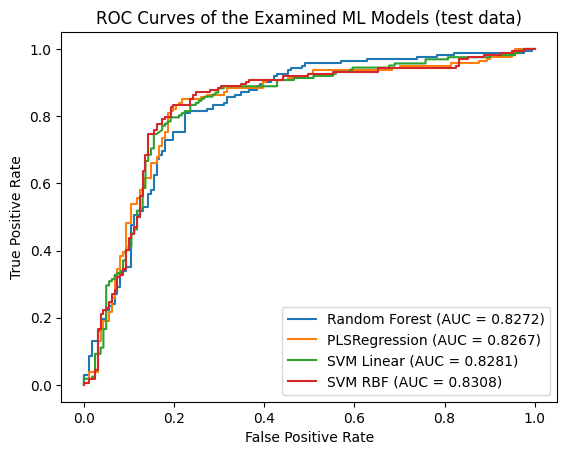

In [ ]:

fpr_rf, tpr_rf, t = roc_curve(y_test, y_pred_rf)
fpr_plsr, tpr_plsr, t = roc_curve(y_test, y_pred_plsr)
fpr_svmLinear, tpr_svmLinear, t = roc_curve(y_test, y_pred_svml)
fpr_svmRBF, tpr_svmRBF, t = roc_curve(y_test, y_pred_svmr)


plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {auc_rf:.4f})')
plt.plot(fpr_plsr, tpr_plsr, label=f'PLSRegression (AUC = {auc_plsr:.4f})')
plt.plot(fpr_svmLinear, tpr_svmLinear, label=f'SVM Linear (AUC = {auc_svml:.4f})')
plt.plot(fpr_svmRBF, tpr_svmRBF, label=f'SVM RBF (AUC = {auc_svmr:.4f})')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves of the Examined ML Models (test data)')
plt.legend()
plt.show()

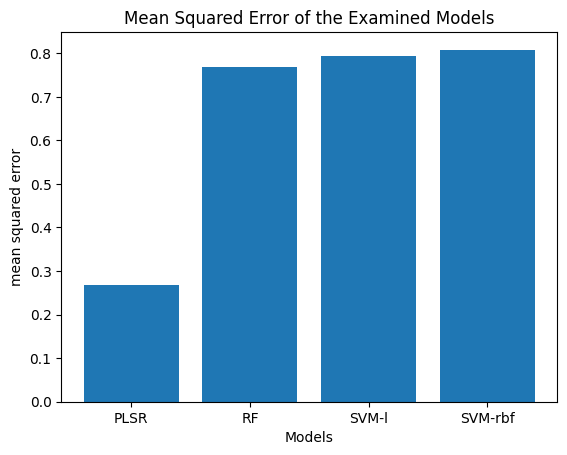

In [ ]:
plt.bar(['PLSR', 'RF', 'SVM-l', 'SVM-rbf'], [sq_er_plsr, sq_er_rf ,sq_er_svml, sq_er_svmr])
plt.title('Mean Squared Error of the Examined Models')
plt.xlabel('Models')
plt.ylabel('mean squared error')
plt.show()